In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
from tqdm import tqdm
import os
import torch
import torch.nn as nn
import pickle

from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.models import densenet121, DenseNet121_Weights
import os
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import (
    inception_v3, Inception_V3_Weights,
    resnet50, ResNet50_Weights,
    densenet121, DenseNet121_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
    swin_t, Swin_T_Weights
)

class BinaryClassifierBase(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return self.model(x)

In [ ]:
from PIL import Image
import os

root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"

for folder, _, files in os.walk(root):
    for file in files:
        path = os.path.join(folder, file)
        try:
            with Image.open(path) as img:
                img.verify()
        except Exception:
            print("Deleting:", path)
            os.remove(path)

EfficientNet

In [11]:
import os
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torch.utils.data import DataLoader
from tqdm import tqdm

# ------------------------
# ECA Layer Definition
# ------------------------
class eca_layer(nn.Module):
    def __init__(self, channel, k_size=3):
        super(eca_layer, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, kernel_size=k_size, padding=(k_size - 1) // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        y = self.avg_pool(x)  # [B, C, 1, 1]
        y = self.conv(y.squeeze(-1).transpose(-1, -2)).transpose(-1, -2).unsqueeze(-1)  # [B, C, 1, 1]
        y = self.sigmoid(y)
        return x * y.expand_as(x)

# ------------------------
# EfficientNet with ECA
# ------------------------
class ProstateCancerEffNetECA(nn.Module):
    def __init__(self):
        super(ProstateCancerEffNetECA, self).__init__()
        effnet = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
        self.backbone = effnet.features
        self.eca = eca_layer(channel=1280, k_size=3)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1280, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.backbone(x)
        x = self.eca(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


In [12]:
import os
import torch
import torch.nn as nn
from torchvision import datasets
from torchvision.models import resnet50, ResNet50_Weights
from torch.utils.data import DataLoader, random_split
from tqdm import tqdm
import pickle

# ------------------------
# ECA Layer (Efficient Channel Attention)
class eca_layer(nn.Module):
    def __init__(self, channel, k_size=3):
        super(eca_layer, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.conv = nn.Conv1d(1, 1, kernel_size=k_size, padding=(k_size - 1) // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        y = self.avg_pool(x)  # [B, C, 1, 1]
        y = self.conv(y.squeeze(-1).transpose(-1, -2)).transpose(-1, -2).unsqueeze(-1)  # [B, C, 1, 1]
        y = self.sigmoid(y)
        return x * y.expand_as(x)
# ------------------------
class ProstateCancerResNetECA(nn.Module):
    def __init__(self, pretrained=True):
        super(ProstateCancerResNetECA, self).__init__()

        # Load ResNet50 backbone
        weights = ResNet50_Weights.DEFAULT if pretrained else None
        resnet = resnet50(weights=weights)

        # Take all layers except the last avgpool and fc
        self.backbone = nn.Sequential(
            resnet.conv1,
            resnet.bn1,
            resnet.relu,
            resnet.maxpool,
            resnet.layer1,
            resnet.layer2,
            resnet.layer3,
            resnet.layer4
        )

        # ECA after final feature layer
        self.eca = eca_layer(channel=2048, k_size=3)

        # Global pooling
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        # Custom classifier head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(2048, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.backbone(x)  # -> (B, 2048, H, W)
        x = self.eca(x)       # -> (B, 2048, H, W)
        x = self.pool(x)      # -> (B, 2048, 1, 1)
        x = self.classifier(x)
        return x



In [6]:
# ------------------------
# Paths & Setup
# ------------------------
data_dir = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Training_and_Validation_resized_256 (copy)"
checkpoint_dir = "/content/drive/MyDrive/Classification/Weights/EfficientNet_B0"
os.makedirs(checkpoint_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
transform = ResNet50_Weights.DEFAULT.transforms()

model = ProstateCancerResNetECA().to(device)

# ------------------------
# Dataset & Dataloader
# ------------------------
full_dataset = datasets.ImageFolder(root=data_dir, transform=transform)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)

# ------------------------
# Loss & Optimizer
# ------------------------
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ------------------------
# Training Setup
# ------------------------
num_epochs = 50

best_val_loss = float('inf')

history = {
    "epoch": [],
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

print(f"Device: {device}")
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Total epochs: {num_epochs}")
print(f"Checkpoint directory: {checkpoint_dir}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 190MB/s]


Device: cuda
Number of training samples: 2364
Number of validation samples: 591
Total epochs: 50
Checkpoint directory: /content/drive/MyDrive/Classification/Weights/EfficientNet_B0


In [ ]:
# ------------------------
# Training Loop
# ------------------------

for epoch in tqdm(range(1, num_epochs + 1), desc="Epochs"):

    # ============================================================
    # TRAINING
    # ============================================================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.float().unsqueeze(1).to(device)

        # Clear gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Accumulate loss
        running_loss += loss.item() * labels.size(0)

        # Predictions
        preds = (outputs > 0.5).float()

        correct += (preds == labels).sum().item()
        total += labels.size(0)

    # Epoch training metrics
    train_loss = running_loss / total
    train_acc = correct / total


    # ============================================================
    # VALIDATION
    # ============================================================
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            # Forward pass
            outputs = model(images)

            # Validation loss
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)

            # Predictions
            preds = (outputs > 0.5).float()

            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    # Epoch validation metrics
    val_loss /= val_total
    val_acc = val_correct / val_total


    # ============================================================
    # STORE HISTORY
    # ============================================================
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)


    # ============================================================
    # SAVE WEIGHTS AFTER EVERY EPOCH
    # ============================================================

    epoch_checkpoint_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_weights.pth"
    )

    torch.save(
        model.state_dict(),
        epoch_checkpoint_path
    )


    # ============================================================
    # SAVE COMPLETE CHECKPOINT
    # ============================================================
    # This is useful if you want to RESUME training later.

    epoch_checkpoint_full_path = os.path.join(
        checkpoint_dir,
        f"epoch_{epoch:02d}_checkpoint.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc
        },
        epoch_checkpoint_full_path
    )


    # ============================================================
    # SAVE BEST MODEL
    # ============================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_model_path = os.path.join(
            checkpoint_dir,
            "best_weights.pth"
        )

        torch.save(
            model.state_dict(),
            best_model_path
        )

        print(
            f"\n✅ New best model saved "
            f"(Epoch {epoch}, Val Loss = {val_loss:.4f})"
        )


    # ============================================================
    # SAVE TRAINING HISTORY AFTER EVERY EPOCH
    # ============================================================

    history_path = os.path.join(
        checkpoint_dir,
        "training_history.pkl"
    )

    with open(history_path, "wb") as f:
        pickle.dump(history, f)


    # ============================================================
    # PRINT EPOCH RESULTS
    # ============================================================

    print(
        f"Epoch {epoch:2d}: "
        f"Train Loss: {train_loss:.4f}, "
        f"Train Acc: {train_acc:.4f}, "
        f"Val Loss: {val_loss:.4f}, "
        f"Val Acc: {val_acc:.4f}"
    )

print("\n" + "=" * 60)
print("TRAINING COMPLETED")
print("=" * 60)
print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"All epoch weights saved in:")
print(checkpoint_dir)

Epochs:   0%|          | 0/50 [00:00<?, ?it/s]


✅ New best model saved (Epoch 1, Val Loss = 0.6159)


Epochs:   2%|▏         | 1/50 [01:16<1:02:50, 76.94s/it]

Epoch  1: Train Loss: 0.5517, Train Acc: 0.7153, Val Loss: 0.6159, Val Acc: 0.7107


Epochs:   4%|▍         | 2/50 [02:26<58:06, 72.63s/it]  

...

Epoch 48: Train Loss: 0.0043, Train Acc: 1.0000, Val Loss: 0.1569, Val Acc: 0.9560


Epochs:  98%|█████████▊| 49/50 [54:25<00:59, 59.46s/it]

Epoch 49: Train Loss: 0.0042, Train Acc: 1.0000, Val Loss: 0.1588, Val Acc: 0.9560


Epochs: 100%|██████████| 50/50 [55:25<00:00, 66.51s/it]

Epoch 50: Train Loss: 0.0038, Train Acc: 1.0000, Val Loss: 0.1733, Val Acc: 0.9526

TRAINING COMPLETED
Best Validation Loss: 0.1387
All epoch weights saved in:
/content/drive/MyDrive/Classification/Weights/EfficientNet_B0


In [17]:
import os
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torchvision.io import read_image
from torchvision.transforms import functional as TF
import pandas as pd
from tqdm import tqdm
import numpy as np

# ----------------------
# Device and Model
# ----------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights = EfficientNet_B0_Weights.DEFAULT
transform = weights.transforms()

# class EfficientNetBinary(nn.Module):
#     def __init__(self):
#         super().__init__()
#         weights = EfficientNet_B0_Weights.DEFAULT
#         self.model = efficientnet_b0(weights=weights)
#         in_features = self.model.classifier[1].in_features
#         self.model.classifier[1] = nn.Sequential(
#             nn.Linear(in_features, 1),
#             nn.Sigmoid()
#         )

#     def forward(self, x):
#         return self.model(x)


model = ProstateCancerResNetECA().to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/Classification/Weights/EfficientNet_B0/epoch_40_weights.pth"))  # ← replace with your path
model.eval()

# ----------------------
# Test folders
# ----------------------
test_root = "/content/drive/MyDrive/Classification/Bt_training_and_testing/Testing_resized_v2"
class_map = {'a_non_cancer': 0, 'b_cancer': 1}

# ----------------------
# Evaluation Loop
# ----------------------
TP = FP = TN = FN = 0
accuracies = []

with torch.no_grad():
    for cls_name, label in class_map.items():
        folder = os.path.join(test_root, cls_name)
        for fname in tqdm(os.listdir(folder), desc=f"Evaluating {cls_name}"):
            if not fname.lower().endswith(('.png', '.jpg', '.jpeg')): continue

            path = os.path.join(folder, fname)
            image = read_image(path).float() / 255.0
            image = transform(image).unsqueeze(0).to(device)

            output = model(image)
            pred = 1 if output.item() > 0.5 else 0

            # Accuracy for deviation
            correct = (pred == label)
            accuracies.append(int(correct))

            # Confusion matrix components
            if pred == 1 and label == 1:
                TP += 1
            elif pred == 1 and label == 0:
                FP += 1
            elif pred == 0 and label == 0:
                TN += 1
            elif pred == 0 and label == 1:
                FN += 1

# ----------------------
# Metrics
# ----------------------
total = TP + FP + TN + FN
accuracy = (TP + TN) / total if total else 0
sensitivity = TP / (TP + FN) if (TP + FN) else 0
specificity = TN / (TN + FP) if (TN + FP) else 0
deviation = np.std(accuracies)

# ----------------------
# Save CSV
# ----------------------
results = {
    'TP': [TP],
    'FP': [FP],
    'TN': [TN],
    'FN': [FN],
    'Accuracy': [round(accuracy, 4)],
    'Sensitivity': [round(sensitivity, 4)],
    'Specificity': [round(specificity, 4)],
    'Accuracy StdDev': [round(deviation, 4)]
}

df = pd.DataFrame(results)
df.to_csv("/content/drive/MyDrive/Classification/Results/EfficientNet_B0/efficientNet_epoch_40.csv", index=False)
print("\n✅ Results saved to 'efficientNet_top_result.csv'")


Evaluating b_cancer: 100%|██████████| 164/164 [00:02<00:00, 78.28it/s]


✅ Results saved to 'efficientNet_top_result.csv'


In [8]:
import torch

weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "EfficientNet_B0/"
    "epoch_40_weights.pth"
)

checkpoint = torch.load(
    weights_path,
    map_location="cpu"
)

print("=" * 70)
print("CHECKPOINT TYPE")
print("=" * 70)

print(type(checkpoint))

if isinstance(checkpoint, dict):

    print("\nNumber of keys:", len(checkpoint))

    print("\nFirst 50 checkpoint keys:")
    for i, key in enumerate(checkpoint.keys()):

        print(f"{i}: {key}")

        if i >= 49:
            break

print("\n" + "=" * 70)

CHECKPOINT TYPE
<class 'collections.OrderedDict'>

Number of keys: 335

First 50 checkpoint keys:
0: backbone.0.weight
1: backbone.1.weight
2: backbone.1.bias
3: backbone.1.running_mean
4: backbone.1.running_var
5: backbone.1.num_batches_tracked
6: backbone.4.0.conv1.weight
7: backbone.4.0.bn1.weight
8: backbone.4.0.bn1.bias
9: backbone.4.0.bn1.running_mean
10: backbone.4.0.bn1.running_var
11: backbone.4.0.bn1.num_batches_tracked
12: backbone.4.0.conv2.weight
13: backbone.4.0.bn2.weight
14: backbone.4.0.bn2.bias
15: backbone.4.0.bn2.running_mean
16: backbone.4.0.bn2.running_var
17: backbone.4.0.bn2.num_batches_tracked
18: backbone.4.0.conv3.weight
19: backbone.4.0.bn3.weight
20: backbone.4.0.bn3.bias
21: backbone.4.0.bn3.running_mean
22: backbone.4.0.bn3.running_var
23: backbone.4.0.bn3.num_batches_tracked
24: backbone.4.0.downsample.0.weight
25: backbone.4.0.downsample.1.weight
26: backbone.4.0.downsample.1.bias
27: backbone.4.0.downsample.1.running_mean
28: backbone.4.0.downsample.1.

DEVICE
cuda

LOADING MODEL
Model loaded successfully.
Weights: /content/drive/MyDrive/Classification/Weights/EfficientNet_B0/epoch_40_weights.pth

TEST DATASET
a_non_cancer (0): 164 images
b_cancer (1): 164 images


Evaluating b_cancer: 100%|██████████| 164/164 [00:02<00:00, 79.13it/s]



Calculating 95% confidence intervals...


FINAL MODEL EVALUATION

CONFUSION MATRIX
----------------------------------------------------------------------
True Positives (TP):   150
False Positives (FP):  11
True Negatives (TN):   153
False Negatives (FN):  14
Total:                 328

PERFORMANCE METRICS
----------------------------------------------------------------------
Accuracy:       0.9238 (92.38%)
Sensitivity:    0.9146 (91.46%)
Specificity:    0.9329 (93.29%)
Precision:      0.9317 (93.17%)
F1-Score:       0.9231
Accuracy StdDev:0.2653
ROC-AUC:        0.9193
PR-AUC:         0.9096

CALIBRATION METRICS
----------------------------------------------------------------------
Brier Score:    0.0748
ECE:            0.0697
MCE:            0.4196

95% CONFIDENCE INTERVALS
----------------------------------------------------------------------
Accuracy:       0.9238 (0.8933, 0.9512)
Sensitivity:    0.9146 (0.8708, 0.9568)
Specificity:    0.9329 (0.8926, 0.9682)
Precision:      0.9317

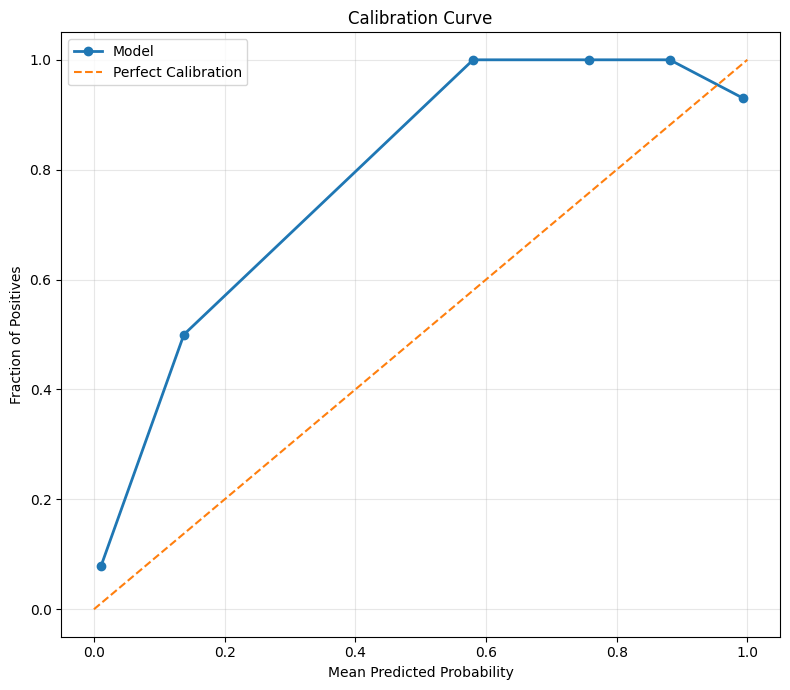

Calibration curve saved to:
/content/drive/MyDrive/Classification/Results/EfficientNet_B0/Calibration_analysis/efficientNet_epoch_40_calibration_curve.png


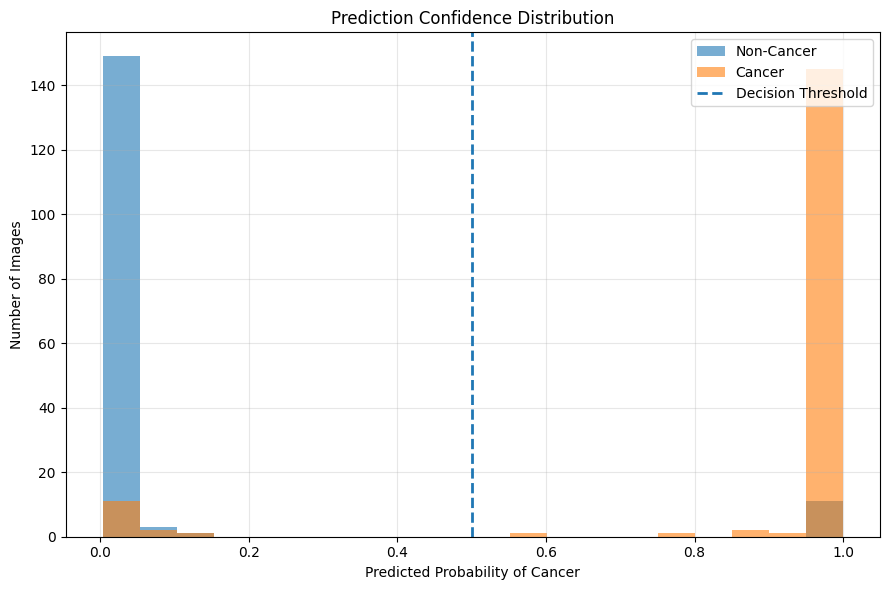

Probability histogram saved to:
/content/drive/MyDrive/Classification/Results/EfficientNet_B0/Calibration_analysis/efficientNet_epoch_40_probability_histogram.png


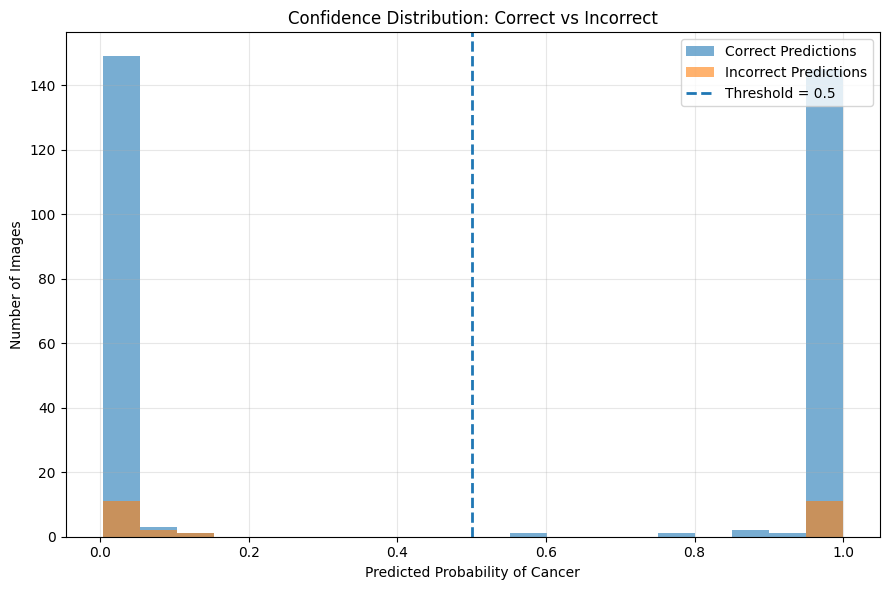

Confidence plot saved to:
/content/drive/MyDrive/Classification/Results/EfficientNet_B0/Calibration_analysis/efficientNet_epoch_40_correct_incorrect_confidence.png

FINAL CHECK
Number of predictions: 328
TP + FP + TN + FN: 328
Accuracy from confusion matrix: 0.9238
Accuracy from predictions: 0.9238
Brier Score: 0.0748
ECE: 0.0697
MCE: 0.4196
EVALUATION COMPLETE


In [23]:
# ============================================================
# COMPLETE MODEL EVALUATION
# Performance + Calibration + Confidence Intervals
#
# Model:
# ProstateCancerResNetECA
#
# Checkpoint:
# EfficientNet_B0/epoch_40_weights.pth
#
# IMPORTANT:
# The architecture and preprocessing are intentionally kept
# exactly as in your existing code so that the classification
# results are not unintentionally changed.
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

import matplotlib.pyplot as plt

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

from torchvision.models import (
    resnet50,
    ResNet50_Weights
)

from torchvision.io import read_image

from tqdm import tqdm

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

from sklearn.calibration import calibration_curve

# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ============================================================
# 2. DEVICE
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("DEVICE")
print("=" * 70)
print(device)

# ============================================================
# 3. PATHS
# ============================================================

weights_path = (
    "/content/drive/MyDrive/"
    "Classification/Weights/"
    "EfficientNet_B0/"
    "epoch_40_weights.pth"
)

test_root = (
    "/content/drive/MyDrive/"
    "Classification/Bt_training_and_testing/"
    "Testing_resized_v2"
)

output_dir = (
    "/content/drive/MyDrive/"
    "Classification/Results/"
    "EfficientNet_B0/Calibration_analysis"
)

os.makedirs(output_dir, exist_ok=True)

# ============================================================
# 4. CLASS MAPPING
# ============================================================

class_map = {
    "a_non_cancer": 0,
    "b_cancer": 1
}

# ============================================================
# 5. PREPROCESSING
# ============================================================
#
# IMPORTANT:
# This is intentionally the SAME preprocessing used in your
# original code.
#
# Even though the model class is ResNet50 + ECA, your existing
# code uses EfficientNet_B0_Weights.DEFAULT.transforms().
#
# We preserve it here to avoid changing your predictions.
# ============================================================

weights = EfficientNet_B0_Weights.DEFAULT
transform = weights.transforms()

# ============================================================
# 6. ECA LAYER
# ============================================================

class eca_layer(nn.Module):

    def __init__(self, channel, k_size=3):

        super(eca_layer, self).__init__()

        self.avg_pool = nn.AdaptiveAvgPool2d(1)

        self.conv = nn.Conv1d(
            1,
            1,
            kernel_size=k_size,
            padding=(k_size - 1) // 2,
            bias=False
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):

        # [B, C, H, W]
        y = self.avg_pool(x)

        # [B, C, 1, 1]
        y = (
            self.conv(
                y.squeeze(-1).transpose(-1, -2)
            )
            .transpose(-1, -2)
            .unsqueeze(-1)
        )

        # [B, C, 1, 1]
        y = self.sigmoid(y)

        return x * y.expand_as(x)


# ============================================================
# 7. PROSTATE CANCER RESNET + ECA MODEL
# ============================================================

class ProstateCancerResNetECA(nn.Module):

    def __init__(self, pretrained=True):

        super(ProstateCancerResNetECA, self).__init__()

        # ----------------------------------------------------
        # ResNet50 backbone
        # ----------------------------------------------------

        resnet_weights = (
            ResNet50_Weights.DEFAULT
            if pretrained
            else None
        )

        resnet = resnet50(
            weights=resnet_weights
        )

        # ----------------------------------------------------
        # Remove average pooling and FC
        # ----------------------------------------------------

        self.backbone = nn.Sequential(

            resnet.conv1,
            resnet.bn1,
            resnet.relu,
            resnet.maxpool,

            resnet.layer1,
            resnet.layer2,
            resnet.layer3,
            resnet.layer4
        )

        # ----------------------------------------------------
        # ECA
        # ----------------------------------------------------

        self.eca = eca_layer(
            channel=2048,
            k_size=3
        )

        # ----------------------------------------------------
        # Global pooling
        # ----------------------------------------------------

        self.pool = nn.AdaptiveAvgPool2d(
            (1, 1)
        )

        # ----------------------------------------------------
        # Classifier
        # ----------------------------------------------------

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                2048,
                512
            ),

            nn.BatchNorm1d(512),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(
                512,
                128
            ),

            nn.BatchNorm1d(128),

            nn.ReLU(),

            nn.Dropout(0.5),

            nn.Linear(
                128,
                1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        x = self.backbone(x)

        x = self.eca(x)

        x = self.pool(x)

        x = self.classifier(x)

        return x


# ============================================================
# 8. LOAD MODEL
# ============================================================

print("\n" + "=" * 70)
print("LOADING MODEL")
print("=" * 70)

model = ProstateCancerResNetECA(
    pretrained=True
).to(device)

checkpoint = torch.load(
    weights_path,
    map_location=device
)

# Handle possible checkpoint formats
if isinstance(checkpoint, dict):

    if "state_dict" in checkpoint:
        checkpoint = checkpoint["state_dict"]

    elif "model_state_dict" in checkpoint:
        checkpoint = checkpoint["model_state_dict"]

# Remove possible "module." prefix
clean_checkpoint = {}

for key, value in checkpoint.items():

    new_key = key

    if new_key.startswith("module."):
        new_key = new_key[7:]

    clean_checkpoint[new_key] = value


# ------------------------------------------------------------
# Load weights
# ------------------------------------------------------------

model.load_state_dict(
    clean_checkpoint,
    strict=True
)

model.eval()

print("Model loaded successfully.")
print("Weights:", weights_path)

# ============================================================
# 9. CHECK TEST DATASET
# ============================================================

print("\n" + "=" * 70)
print("TEST DATASET")
print("=" * 70)

for cls_name, label in class_map.items():

    folder = os.path.join(
        test_root,
        cls_name
    )

    if os.path.exists(folder):

        files = [
            f for f in os.listdir(folder)
            if f.lower().endswith(
                (".png", ".jpg", ".jpeg")
            )
        ]

        print(
            f"{cls_name} ({label}): "
            f"{len(files)} images"
        )

    else:

        print(
            f"WARNING: folder does not exist: "
            f"{folder}"
        )

# ============================================================
# 10. EVALUATION
# ============================================================

TP = 0
FP = 0
TN = 0
FN = 0

accuracies = []

all_probabilities = []
all_predictions = []
all_labels = []
all_filenames = []
all_paths = []

# ------------------------------------------------------------
# IMPORTANT:
# Do NOT use torch.inference_mode() here.
# Regular no_grad is sufficient.
# ------------------------------------------------------------

with torch.no_grad():

    for cls_name, label in class_map.items():

        folder = os.path.join(
            test_root,
            cls_name
        )

        if not os.path.exists(folder):

            print(
                f"Skipping missing folder: {folder}"
            )

            continue

        filenames = sorted(
            os.listdir(folder)
        )

        for fname in tqdm(
            filenames,
            desc=f"Evaluating {cls_name}"
        ):

            if not fname.lower().endswith(
                (".png", ".jpg", ".jpeg")
            ):
                continue

            path = os.path.join(
                folder,
                fname
            )

            try:

                # ------------------------------------------------
                # Read image
                # ------------------------------------------------

                image = read_image(
                    path
                ).float() / 255.0

                # ------------------------------------------------
                # Apply EXACT preprocessing
                # ------------------------------------------------

                image = transform(
                    image
                )

                # ------------------------------------------------
                # Move to device
                # ------------------------------------------------

                image = image.unsqueeze(0).to(device)

                # ------------------------------------------------
                # Model prediction
                # ------------------------------------------------

                output = model(image)

                probability = float(
                    output.squeeze().item()
                )

                # ------------------------------------------------
                # Binary threshold = 0.5
                # ------------------------------------------------

                pred = (
                    1
                    if probability > 0.5
                    else 0
                )

                # ------------------------------------------------
                # Store results
                # ------------------------------------------------

                all_probabilities.append(
                    probability
                )

                all_predictions.append(
                    pred
                )

                all_labels.append(
                    label
                )

                all_filenames.append(
                    fname
                )

                all_paths.append(
                    path
                )

                # ------------------------------------------------
                # Accuracy deviation
                # ------------------------------------------------

                correct = (
                    pred == label
                )

                accuracies.append(
                    int(correct)
                )

                # ------------------------------------------------
                # Confusion matrix
                # ------------------------------------------------

                if pred == 1 and label == 1:

                    TP += 1

                elif pred == 1 and label == 0:

                    FP += 1

                elif pred == 0 and label == 0:

                    TN += 1

                elif pred == 0 and label == 1:

                    FN += 1

            except Exception as e:

                print(
                    f"\nError processing {path}: {e}"
                )

# ============================================================
# 11. CONVERT TO NUMPY
# ============================================================

all_probabilities = np.asarray(
    all_probabilities,
    dtype=np.float64
)

all_predictions = np.asarray(
    all_predictions,
    dtype=np.int64
)

all_labels = np.asarray(
    all_labels,
    dtype=np.int64
)

accuracies = np.asarray(
    accuracies,
    dtype=np.float64
)

# ============================================================
# 12. BASIC METRICS
# ============================================================

total = (
    TP + FP + TN + FN
)

accuracy = (
    (TP + TN) / total
    if total
    else 0
)

sensitivity = (
    TP / (TP + FN)
    if (TP + FN)
    else 0
)

specificity = (
    TN / (TN + FP)
    if (TN + FP)
    else 0
)

precision = (
    TP / (TP + FP)
    if (TP + FP)
    else 0
)

f1_score = (
    2 * precision * sensitivity
    / (precision + sensitivity)
    if (precision + sensitivity)
    else 0
)

accuracy_stddev = (
    np.std(accuracies)
    if len(accuracies) > 0
    else 0
)

# ============================================================
# 13. ROC-AUC
# ============================================================

try:

    roc_auc = roc_auc_score(
        all_labels,
        all_probabilities
    )

except Exception:

    roc_auc = np.nan


# ============================================================
# 14. PR-AUC
# ============================================================

try:

    pr_auc = average_precision_score(
        all_labels,
        all_probabilities
    )

except Exception:

    pr_auc = np.nan


# ============================================================
# 15. BRIER SCORE
# ============================================================
#
# Brier Score:
#
#      1/N * SUM((p_i - y_i)^2)
#
# Lower = better calibration.
#
# Perfect = 0
# ============================================================

brier_score = np.mean(
    (
        all_probabilities
        - all_labels
    ) ** 2
)

# ============================================================
# 16. ECE AND MCE
# ============================================================
#
# ECE = weighted average calibration error
#
# MCE = maximum calibration error
#
# We use 10 equal-width bins:
#
# [0.0,0.1)
# [0.1,0.2)
# ...
# [0.9,1.0]
#
# ============================================================

def calculate_calibration_metrics(
    probabilities,
    labels,
    n_bins=10
):

    probabilities = np.asarray(
        probabilities
    )

    labels = np.asarray(
        labels
    )

    bin_edges = np.linspace(
        0.0,
        1.0,
        n_bins + 1
    )

    ece = 0.0
    mce = 0.0

    calibration_rows = []

    n = len(probabilities)

    for i in range(n_bins):

        lower = bin_edges[i]
        upper = bin_edges[i + 1]

        if i == n_bins - 1:

            mask = (
                (probabilities >= lower)
                &
                (probabilities <= upper)
            )

        else:

            mask = (
                (probabilities >= lower)
                &
                (probabilities < upper)
            )

        bin_probabilities = probabilities[
            mask
        ]

        bin_labels = labels[
            mask
        ]

        count = len(
            bin_probabilities
        )

        if count == 0:

            avg_confidence = np.nan
            observed_accuracy = np.nan
            calibration_error = np.nan

        else:

            avg_confidence = np.mean(
                bin_probabilities
            )

            observed_accuracy = np.mean(
                bin_labels
            )

            calibration_error = abs(
                observed_accuracy
                - avg_confidence
            )

            # ECE
            ece += (
                count / n
            ) * calibration_error

            # MCE
            mce = max(
                mce,
                calibration_error
            )

        calibration_rows.append({

            "Bin": i + 1,

            "Lower": lower,

            "Upper": upper,

            "Count": count,

            "Mean_Confidence":
                avg_confidence,

            "Observed_Accuracy":
                observed_accuracy,

            "Absolute_Error":
                calibration_error
        })

    calibration_df = pd.DataFrame(
        calibration_rows
    )

    return (
        ece,
        mce,
        calibration_df
    )


ECE, MCE, calibration_df = (
    calculate_calibration_metrics(
        all_probabilities,
        all_labels,
        n_bins=10
    )
)

# ============================================================
# 17. CALIBRATION CURVE
# ============================================================

prob_true, prob_pred = calibration_curve(
    all_labels,
    all_probabilities,
    n_bins=10,
    strategy="uniform"
)

# ============================================================
# 18. 95% CONFIDENCE INTERVAL
# ============================================================
#
# Bootstrap confidence intervals.
#
# 2000 bootstrap samples.
#
# This DOES NOT mean 2000 test images.
#
# It means 2000 resamples of the existing test predictions.
# ============================================================

def bootstrap_ci(
    labels,
    probabilities,
    metric_function,
    n_bootstrap=2000,
    confidence=0.95,
    seed=42
):

    rng = np.random.default_rng(seed)

    labels = np.asarray(
        labels
    )

    probabilities = np.asarray(
        probabilities
    )

    n = len(labels)

    bootstrap_values = []

    for _ in range(
        n_bootstrap
    ):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        sample_labels = labels[
            indices
        ]

        sample_probabilities = probabilities[
            indices
        ]

        try:

            value = metric_function(
                sample_labels,
                sample_probabilities
            )

            if np.isfinite(value):

                bootstrap_values.append(
                    value
                )

        except Exception:

            continue

    bootstrap_values = np.asarray(
        bootstrap_values
    )

    alpha = (
        1 - confidence
    )

    lower = np.percentile(
        bootstrap_values,
        100 * alpha / 2
    )

    upper = np.percentile(
        bootstrap_values,
        100 * (1 - alpha / 2)
    )

    return lower, upper


# ------------------------------------------------------------
# Metric functions for bootstrap
# ------------------------------------------------------------

def metric_accuracy(
    y,
    p
):

    pred = (
        p > 0.5
    ).astype(int)

    return np.mean(
        pred == y
    )


def metric_sensitivity(
    y,
    p
):

    pred = (
        p > 0.5
    ).astype(int)

    tp = np.sum(
        (pred == 1)
        &
        (y == 1)
    )

    fn = np.sum(
        (pred == 0)
        &
        (y == 1)
    )

    return (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )


def metric_specificity(
    y,
    p
):

    pred = (
        p > 0.5
    ).astype(int)

    tn = np.sum(
        (pred == 0)
        &
        (y == 0)
    )

    fp = np.sum(
        (pred == 1)
        &
        (y == 0)
    )

    return (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


def metric_precision(
    y,
    p
):

    pred = (
        p > 0.5
    ).astype(int)

    tp = np.sum(
        (pred == 1)
        &
        (y == 1)
    )

    fp = np.sum(
        (pred == 1)
        &
        (y == 0)
    )

    return (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )


def metric_f1(
    y,
    p
):

    pred = (
        p > 0.5
    ).astype(int)

    tp = np.sum(
        (pred == 1)
        &
        (y == 1)
    )

    fp = np.sum(
        (pred == 1)
        &
        (y == 0)
    )

    fn = np.sum(
        (pred == 0)
        &
        (y == 1)
    )

    precision_value = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    sensitivity_value = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    return (
        2
        * precision_value
        * sensitivity_value
        /
        (precision_value + sensitivity_value)
        if (
            precision_value
            + sensitivity_value
        ) > 0
        else np.nan
    )


# ============================================================
# 19. CALCULATE CONFIDENCE INTERVALS
# ============================================================

print("\nCalculating 95% confidence intervals...")

accuracy_ci = bootstrap_ci(
    all_labels,
    all_probabilities,
    metric_accuracy
)

sensitivity_ci = bootstrap_ci(
    all_labels,
    all_probabilities,
    metric_sensitivity
)

specificity_ci = bootstrap_ci(
    all_labels,
    all_probabilities,
    metric_specificity
)

precision_ci = bootstrap_ci(
    all_labels,
    all_probabilities,
    metric_precision
)

f1_ci = bootstrap_ci(
    all_labels,
    all_probabilities,
    metric_f1
)

# ============================================================
# 20. PRINT FINAL RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("FINAL MODEL EVALUATION")
print("=" * 70)

print("\nCONFUSION MATRIX")
print("-" * 70)

print(
    f"True Positives (TP):   {TP}"
)

print(
    f"False Positives (FP):  {FP}"
)

print(
    f"True Negatives (TN):   {TN}"
)

print(
    f"False Negatives (FN):  {FN}"
)

print(
    f"Total:                 {total}"
)

print("\nPERFORMANCE METRICS")
print("-" * 70)

print(
    f"Accuracy:       {accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Sensitivity:    {sensitivity:.4f} "
    f"({sensitivity * 100:.2f}%)"
)

print(
    f"Specificity:    {specificity:.4f} "
    f"({specificity * 100:.2f}%)"
)

print(
    f"Precision:      {precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"F1-Score:       {f1_score:.4f}"
)

print(
    f"Accuracy StdDev:{accuracy_stddev:.4f}"
)

print(
    f"ROC-AUC:        {roc_auc:.4f}"
)

print(
    f"PR-AUC:         {pr_auc:.4f}"
)

print("\nCALIBRATION METRICS")
print("-" * 70)

print(
    f"Brier Score:    {brier_score:.4f}"
)

print(
    f"ECE:            {ECE:.4f}"
)

print(
    f"MCE:            {MCE:.4f}"
)

print("\n95% CONFIDENCE INTERVALS")
print("-" * 70)

print(
    f"Accuracy:       "
    f"{accuracy:.4f} "
    f"({accuracy_ci[0]:.4f}, "
    f"{accuracy_ci[1]:.4f})"
)

print(
    f"Sensitivity:    "
    f"{sensitivity:.4f} "
    f"({sensitivity_ci[0]:.4f}, "
    f"{sensitivity_ci[1]:.4f})"
)

print(
    f"Specificity:    "
    f"{specificity:.4f} "
    f"({specificity_ci[0]:.4f}, "
    f"{specificity_ci[1]:.4f})"
)

print(
    f"Precision:      "
    f"{precision:.4f} "
    f"({precision_ci[0]:.4f}, "
    f"{precision_ci[1]:.4f})"
)

print(
    f"F1-Score:       "
    f"{f1_score:.4f} "
    f"({f1_ci[0]:.4f}, "
    f"{f1_ci[1]:.4f})"
)

print("=" * 70)

# ============================================================
# 21. SAVE MAIN RESULTS CSV
# ============================================================

results = {

    "Model": [
        "ProstateCancerResNetECA"
    ],

    "Weights": [
        weights_path
    ],

    "TP": [TP],

    "FP": [FP],

    "TN": [TN],

    "FN": [FN],

    "Total": [total],

    "Accuracy": [
        round(accuracy, 4)
    ],

    "Accuracy_CI_Lower": [
        round(
            accuracy_ci[0],
            4
        )
    ],

    "Accuracy_CI_Upper": [
        round(
            accuracy_ci[1],
            4
        )
    ],

    "Sensitivity": [
        round(
            sensitivity,
            4
        )
    ],

    "Sensitivity_CI_Lower": [
        round(
            sensitivity_ci[0],
            4
        )
    ],

    "Sensitivity_CI_Upper": [
        round(
            sensitivity_ci[1],
            4
        )
    ],

    "Specificity": [
        round(
            specificity,
            4
        )
    ],

    "Specificity_CI_Lower": [
        round(
            specificity_ci[0],
            4
        )
    ],

    "Specificity_CI_Upper": [
        round(
            specificity_ci[1],
            4
        )
    ],

    "Precision": [
        round(
            precision,
            4
        )
    ],

    "Precision_CI_Lower": [
        round(
            precision_ci[0],
            4
        )
    ],

    "Precision_CI_Upper": [
        round(
            precision_ci[1],
            4
        )
    ],

    "F1-Score": [
        round(
            f1_score,
            4
        )
    ],

    "F1_CI_Lower": [
        round(
            f1_ci[0],
            4
        )
    ],

    "F1_CI_Upper": [
        round(
            f1_ci[1],
            4
        )
    ],

    "Accuracy_StdDev": [
        round(
            accuracy_stddev,
            4
        )
    ],

    "ROC_AUC": [
        round(
            roc_auc,
            4
        )
    ],

    "PR_AUC": [
        round(
            pr_auc,
            4
        )
    ],

    "Brier_Score": [
        round(
            brier_score,
            4
        )
    ],

    "ECE": [
        round(
            ECE,
            4
        )
    ],

    "MCE": [
        round(
            MCE,
            4
        )
    ]
}

results_df = pd.DataFrame(
    results
)

results_csv = os.path.join(
    output_dir,
    "efficientNet_epoch_40_all_metrics.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

print(
    f"\nMain metrics saved to:\n"
    f"{results_csv}"
)

# ============================================================
# 22. SAVE DETAILED PREDICTIONS
# ============================================================

detailed_results = pd.DataFrame({

    "Filename":
        all_filenames,

    "Path":
        all_paths,

    "True_Label":
        all_labels,

    "Predicted_Label":
        all_predictions,

    "Probability_Cancer":
        all_probabilities,

    "Correct":
        (
            all_predictions
            == all_labels
        ).astype(int)
})

detailed_csv = os.path.join(
    output_dir,
    "efficientNet_epoch_40_detailed_predictions.csv"
)

detailed_results.to_csv(
    detailed_csv,
    index=False
)

print(
    f"Detailed predictions saved to:\n"
    f"{detailed_csv}"
)

# ============================================================
# 23. SAVE CALIBRATION BINS
# ============================================================

calibration_csv = os.path.join(
    output_dir,
    "efficientNet_epoch_40_calibration_bins.csv"
)

calibration_df.to_csv(
    calibration_csv,
    index=False
)

print(
    f"Calibration bins saved to:\n"
    f"{calibration_csv}"
)

# ============================================================
# 24. CALIBRATION CURVE PLOT
# ============================================================

plt.figure(
    figsize=(8, 7)
)

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    linewidth=2,
    label="Model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel(
    "Mean Predicted Probability"
)

plt.ylabel(
    "Fraction of Positives"
)

plt.title(
    "Calibration Curve"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

calibration_plot = os.path.join(
    output_dir,
    "efficientNet_epoch_40_calibration_curve.png"
)

plt.savefig(
    calibration_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Calibration curve saved to:\n"
    f"{calibration_plot}"
)

# ============================================================
# 25. CONFIDENCE / PROBABILITY HISTOGRAM
# ============================================================

plt.figure(
    figsize=(9, 6)
)

plt.hist(
    all_probabilities[
        all_labels == 0
    ],
    bins=20,
    alpha=0.6,
    label="Non-Cancer"
)

plt.hist(
    all_probabilities[
        all_labels == 1
    ],
    bins=20,
    alpha=0.6,
    label="Cancer"
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Decision Threshold"
)

plt.xlabel(
    "Predicted Probability of Cancer"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "Prediction Confidence Distribution"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

histogram_plot = os.path.join(
    output_dir,
    "efficientNet_epoch_40_probability_histogram.png"
)

plt.savefig(
    histogram_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Probability histogram saved to:\n"
    f"{histogram_plot}"
)

# ============================================================
# 26. CONFIDENCE HISTOGRAM FOR CORRECT VS INCORRECT
# ============================================================

correct_mask = (
    all_predictions
    == all_labels
)

plt.figure(
    figsize=(9, 6)
)

plt.hist(
    all_probabilities[
        correct_mask
    ],
    bins=20,
    alpha=0.6,
    label="Correct Predictions"
)

plt.hist(
    all_probabilities[
        ~correct_mask
    ],
    bins=20,
    alpha=0.6,
    label="Incorrect Predictions"
)

plt.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Threshold = 0.5"
)

plt.xlabel(
    "Predicted Probability of Cancer"
)

plt.ylabel(
    "Number of Images"
)

plt.title(
    "Confidence Distribution: Correct vs Incorrect"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

confidence_plot = os.path.join(
    output_dir,
    "efficientNet_epoch_40_correct_incorrect_confidence.png"
)

plt.savefig(
    confidence_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Confidence plot saved to:\n"
    f"{confidence_plot}"
)

# ============================================================
# 27. FINAL CHECK
# ============================================================

print("\n" + "=" * 70)
print("FINAL CHECK")
print("=" * 70)

print(
    f"Number of predictions: "
    f"{len(all_labels)}"
)

print(
    f"TP + FP + TN + FN: "
    f"{TP + FP + TN + FN}"
)

print(
    f"Accuracy from confusion matrix: "
    f"{(TP + TN) / total:.4f}"
)

print(
    f"Accuracy from predictions: "
    f"{np.mean(all_predictions == all_labels):.4f}"
)

print(
    f"Brier Score: "
    f"{brier_score:.4f}"
)

print(
    f"ECE: "
    f"{ECE:.4f}"
)

print(
    f"MCE: "
    f"{MCE:.4f}"
)

print("=" * 70)
print("EVALUATION COMPLETE")
print("=" * 70)